# 4. Timing analysis

**Solution to the exercise proposed in the `exercise.ipynb`**

## Goal
Produce a light curve of *Mrk 421* in two energy bands, compute the ratio of the fluxes and see if there is any hint of spectral variability. For this, we will learn how to produce a light curve with `gammapy` and perform different calculations over it.

## Prerequisites
Make sure to have read `README.md` in this directory with pre-requisites instructions on required extra dependencies and datasets used in this exercise.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.style as style
style.use('tableau-colorblind10')

import numpy as np

from astropy import units as u
from astropy.coordinates import SkyCoord, Angle
from astropy.time import Time
from astroquery.simbad import Simbad
from regions import CircleSkyRegion
from IPython.display import display

from gammapy.data import DataStore
from gammapy.datasets import SpectrumDataset
from gammapy.estimators import FluxPointsEstimator, LightCurveEstimator
from gammapy.estimators.utils import (
    compute_lightcurve_fvar,
    compute_lightcurve_fpp,
    compute_lightcurve_doublingtime,
    get_rebinned_axis,
    resample_energy_edges,
)
from gammapy.makers import (
    DatasetsMaker,
    SafeMaskMaker,
    SpectrumDatasetMaker,
    ReflectedRegionsBackgroundMaker,
)
from gammapy.maps import MapAxis, RegionGeom, WcsGeom
from gammapy.modeling import Fit
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel
from gammapy.utils import pbar
pbar.SHOW_PROGRESS_BAR = True

### First load the relevant data set

In [2]:
data_store = DataStore.from_dir("../../CTA-SDC-school")

In [3]:
data_store.obs_table

OBS_ID,TSTART,TSTOP,ONTIME,LIVETIME,DEADC,TELESCOP,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,OBJECT,EVENTS_FILENAME,EVENT_COUNT,CALDB,IRF,IRF_FILENAME,MJDREFI,MJDREFF,TIMEUNIT,TIMESYS,TIMEREF
,s,s,s,s,,,deg,deg,deg,deg,,,,,,,,,,,,,,,,
int64,float64,float64,float64,float64,float64,bytes3,float64,float64,float64,float64,bytes13,bytes13,bytes13,bytes13,bytes1,bytes23,bytes48,int64,bytes13,bytes104,bytes106,int64,float64,bytes1,bytes3,bytes5
5000000001,0.0,1795.0000002980232,1795.0000002980232,1795.0000002980232,1.0,CTA,54.64882518615157,56.71474555438274,144.38720815854757,0.9743022266864938,2028-01-01,00:00:00.000,2028-01-01,00:29:55.000,--,pwn2525,products_SDC/Events/North/events_5000000001.fits,117231,prod5,CALDB/CTA-Performance-prod5-v0.1-North-40deg,Prod5-North-40deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000002,1800.0000002095476,3599.9999997904574,1799.9999995809096,1799.9999995809096,1.0,CTA,59.01512317789801,54.78262179202951,147.51270816067023,0.9743023483290738,2028-01-01,00:30:00.000,2028-01-01,01:00:00.000,--,pwn1714,products_SDC/Events/North/events_5000000002.fits,117971,prod5,CALDB/CTA-Performance-prod5-v0.1-North-40deg,Prod5-North-40deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000003,4539.9900003103585,9339.99000024051,4799.999999930151,4799.999999930151,1.0,CTA,148.96845538906777,70.3796977843647,140.66554846777962,40.15624845623681,2028-01-01,01:15:39.990,2028-01-01,02:35:39.990,--,NOT AVAILABLE,products_SDC/Events/North/events_5000000003.fits,312431,prod5,CALDB/CTA-Performance-prod5-v0.1-North-40deg,Prod5-North-40deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000004,7896.0000000894115,9940.99999973551,2044.9999996460974,2044.9999996460974,1.0,CTA,128.4129133102239,-45.047528021114566,263.27000000000004,-2.9500000000000655,2028-01-01,02:11:36.000,2028-01-01,02:45:41.000,--,pwn2141,products_SDC/Events/South/events_5000000004.fits,26641,prod5,CALDB/CTA-Performance-prod5-v0.1-South-60deg,Prod5-South-60deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000005,9339.99000024051,14139.990000170661,4799.999999930151,4799.999999930151,1.0,CTA,148.96845538906777,68.97969778436467,142.16253042854933,40.972848927846826,2028-01-01,02:35:39.990,2028-01-01,03:55:39.990,--,NOT AVAILABLE,products_SDC/Events/North/events_5000000005.fits,312857,prod5,CALDB/CTA-Performance-prod5-v0.1-North-40deg,Prod5-North-40deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000006,9946.000000275677,16895.999999879863,6949.999999604188,6949.999999604188,1.0,CTA,128.4129133102239,-45.047528021114566,263.27000000000004,-2.9500000000000655,2028-01-01,02:45:46.000,2028-01-01,04:41:36.000,--,pwn2141,products_SDC/Events/South/events_5000000006.fits,377388,prod5,CALDB/CTA-Performance-prod5-v0.1-South-40deg,Prod5-South-40deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000007,14139.990000170661,18939.99000010081,4799.999999930151,4799.999999930151,1.0,CTA,150.98345901018118,69.66815396126067,140.8673410892068,41.134274175683515,2028-01-01,03:55:39.990,2028-01-01,05:15:39.990,--,NOT AVAILABLE,products_SDC/Events/North/events_5000000007.fits,313345,prod5,CALDB/CTA-Performance-prod5-v0.1-North-40deg,Prod5-North-40deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL
5000000008,16895.999999879863,17131.000000122007,235.00000024214387,235.00000024214387,1.0,CTA,128.4129133102239,-45.047528021114566,263.27000000000004,-2.9500000000000655,2028-01-01,04:41:36.000,2028-01-01,04:45:31.000,--,pwn2141,products_SDC/Events/South/events_5000000008.fits,12745,prod5,CALDB/CTA-Performance-prod5-v0.1-South-40deg,Prod5-South-40deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz,61771,0.0,s,utc,LOCAL


### Set the properties of the source of interest

*Bonus*: we can use Virtual Observatory services to query some other source parameters, like its redshift.

In [4]:
src = dict()
src['Name'] = 'Mrk 421'
src['Position'] = SkyCoord.from_name(src['Name'])

try:
    simbad = Simbad()
    simbad.add_votable_fields("rvz_redshift")
    query = simbad.query_object(src['Name'])
    src['Redshift'] = query["rvz_redshift"].data[0]
except NameError:
    print("Cannot use Simbad, will set the source redshift manually")
    src['Redshift'] = 0.030  # For Mrk 421

### Data selection
We select a subsample of data acquired on our source of interest

In [5]:
selection = dict(
    type="sky_circle",
    frame="icrs",
    lon=src['Position'].ra,
    lat=src['Position'].dec,
    radius="3 deg",
)
selected_obs_table = data_store.obs_table.select_observations(selection)

selection = dict(
    type="time_box",
    time_range=Time(["2028-01-01T12:00", "2028-01-30T12:00"]),
)
selected_obs_table = selected_obs_table.select_observations(selection)

# Or select the runs manually
# selected_obs_table = selected_obs_table[0:20]

obs_ids = selected_obs_table["OBS_ID"]
observations = data_store.get_observations(obs_ids)

Obs Id:   0%|          | 0/20 [00:00<?, ?it/s]

Let's create 20-min bin time intervals, for later use, and filter the observations on it:

In [6]:
t0 = observations[0].tstart
duration = 20 * u.min
n_time_bins = int((observations[-1].tstop - t0) / duration) + 1
times = t0 + np.arange(n_time_bins) * duration
time_intervals = [Time([tstart, tstop]) for tstart, tstop in zip(times[:-1], times[1:])]
print(time_intervals)

short_observations = observations.select_time(time_intervals)

[<Time object: scale='utc' format='mjd' value=[61774.25268507 61774.26657396]>, <Time object: scale='utc' format='mjd' value=[61774.26657396 61774.28046285]>, <Time object: scale='utc' format='mjd' value=[61774.28046285 61774.29435174]>, <Time object: scale='utc' format='mjd' value=[61774.29435174 61774.30824062]>, <Time object: scale='utc' format='mjd' value=[61774.30824062 61774.32212951]>, <Time object: scale='utc' format='mjd' value=[61774.32212951 61774.3360184 ]>, <Time object: scale='utc' format='mjd' value=[61774.3360184  61774.34990729]>, <Time object: scale='utc' format='mjd' value=[61774.34990729 61774.36379618]>, <Time object: scale='utc' format='mjd' value=[61774.36379618 61774.37768507]>, <Time object: scale='utc' format='mjd' value=[61774.37768507 61774.39157396]>, <Time object: scale='utc' format='mjd' value=[61774.39157396 61774.40546285]>, <Time object: scale='utc' format='mjd' value=[61774.40546285 61774.41935174]>, <Time object: scale='utc' format='mjd' value=[61774

In [7]:
# Or just observation by observation:
# time_intervals = [Time([obs.tstart, obs.tstop]) for obs in observations]
# short_observations = observations

# Data reduction

Let's perform a 1D analysis of the data.

In [8]:
on_region_radius = Angle("0.1 deg")

on_region = CircleSkyRegion(center=src['Position'], radius=on_region_radius)
exclusion_region = CircleSkyRegion(center=src['Position'], radius=0.5 * u.deg)
geom = WcsGeom.create(
    npix=(120, 120), binsz=0.05, skydir=src['Position'], proj="TAN", frame="icrs"
)
exclusion_mask = ~geom.region_mask([exclusion_region])

In [9]:
energy_axis = MapAxis.from_energy_bounds(0.02, 200, nbin=5, per_decade=True, unit="TeV", name="energy")
energy_axis_true = MapAxis.from_energy_bounds(0.005, 300, nbin=10, per_decade=True, unit="TeV", name="energy_true")

geom = RegionGeom.create(region=on_region, axes=[energy_axis])

dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)
dataset_maker = SpectrumDatasetMaker(containment_correction=True, selection=["counts", "exposure", "edisp"])

bkg_maker = ReflectedRegionsBackgroundMaker(exclusion_mask=exclusion_mask)
safe_mask_maker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=10)

In [10]:
%%time

# Parallel version
makers = [dataset_maker, bkg_maker, safe_mask_maker]  # the order matters
datasets_maker = DatasetsMaker(makers, stack_datasets=False, n_jobs=6)
datasets = datasets_maker.run(dataset_empty, observations)

Data reduction:   0%|          | 0/20 [00:00<?, ?it/s]

CPU times: user 959 ms, sys: 74.8 ms, total: 1.03 s
Wall time: 3.6 s


In [11]:
dataset_stack = datasets.stack_reduce()

Let's find some energy at which to slice our data, to build two well-balanced sets into two energy bands:

In [12]:
excess = dataset_stack.excess.data.T[0][0]
mask = excess > 0
excess = excess[mask]
energy_bins = dataset_stack.counts.geom.axes['energy'].center[mask]
split_value = 2./3. * np.sum(excess)
split_mask = np.cumsum(excess) > split_value
e_split = energy_bins[split_mask][0]

print(f'Split energy: {e_split:.3f}')

Split energy: 0.632 TeV


In [13]:
e_min = dataset_stack.energy_range_safe[0].data[0][0] * dataset_stack.energy_range_safe[0].unit
e_max = dataset_stack.energy_range_safe[-1].data[0][0] * dataset_stack.energy_range_safe[0].unit
print(f'Energy threshold: {e_min:.3f}')
print(f'Maximal energy: {e_max:.3f}')

Energy threshold: 0.200 TeV
Maximal energy: 200.000 TeV


# Fit overall spectrum

In [14]:
spectral_model = PowerLawSpectralModel(
    amplitude=1.0e-11 * u.Unit("cm-2 s-1 TeV-1"),
    reference=e_split,
    index=2.
)
spectral_model.parameters["amplitude"].frozen = False
spectral_model.parameters["index"].frozen = False

In [15]:
source_skymodel = SkyModel(
    spectral_model=spectral_model,
    name=src["Name"]
)

for dataset in datasets:
    dataset.models = source_skymodel

In [16]:
%%time

fit_joint = Fit()
result_joint = fit_joint.run(datasets=datasets)

# We make a copy here of the optimized model for later use
model_best_joint = source_skymodel.copy(name=src["Name"])

CPU times: user 2.11 s, sys: 5.53 ms, total: 2.11 s
Wall time: 2.11 s


In [17]:
print(result_joint)
display(result_joint.models.to_parameters_table())

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 72
	total stat : 2258.74

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



model,type,name,value,unit,error,min,max,frozen,link,prior
str7,str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
Mrk 421,,index,3.0508e+00,,2.287e-02,nan,nan,False,,
Mrk 421,,amplitude,9.9703e-11,TeV-1 s-1 cm-2,1.622e-12,nan,nan,False,,
Mrk 421,,reference,6.3246e-01,TeV,0.000e+00,nan,nan,True,,


## Compute SED flux points

In [18]:
%%time

energy_edges = resample_energy_edges(dataset_stack, conditions={'sqrt_ts_min': 2.})

fpe = FluxPointsEstimator(
    energy_edges=energy_edges,
    source=src["Name"],
    selection_optional=["errn-errp", "ul", "scan"],
    fit=fit_joint,
    n_jobs=6,
)
flux_points = fpe.run(datasets)

Energy bins:   0%|          | 0/7 [00:00<?, ?it/s]

Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend


Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

...

Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

Reoptimize = False ignored for iminuit backend
Reoptimize = False ignored for iminuit backend


Scan values:   0%|          | 0/11 [00:00<?, ?it/s]

CPU times: user 1.57 s, sys: 220 ms, total: 1.79 s
Wall time: 17.8 s


/cvmfs/sw.hess-experiment.eu/software/conda/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='e2dnde [$\\mathrm{erg\\,s^{-1}\\,cm^{-2}}$]'>

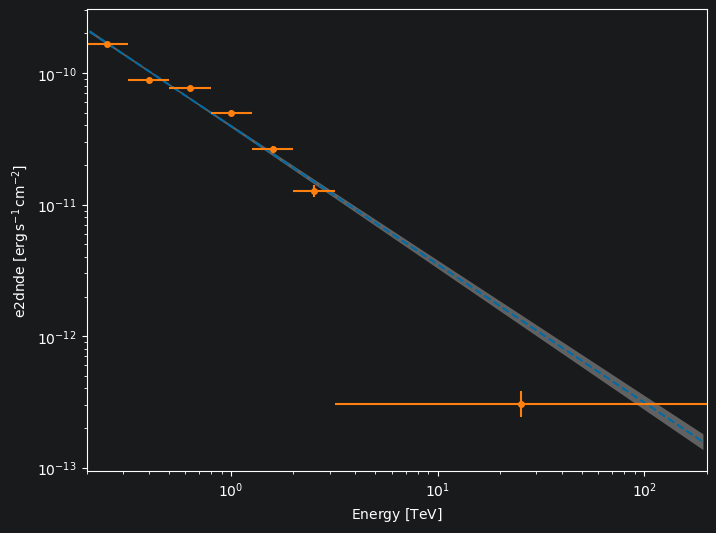

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

plot_kwargs = {
    "energy_bounds": [e_min, e_max],
    "sed_type": "e2dnde",
    "ax": ax,
}

# plot joint model
model_best_joint.spectral_model.plot(
    **plot_kwargs, ls="--"
)
model_best_joint.spectral_model.plot_error(facecolor="grey", alpha=0.7, **plot_kwargs)

flux_points.plot(ax=plot_kwargs["ax"],
                 sed_type=plot_kwargs["sed_type"],
                 )

# Light curve

Let's compute the light curve in two energy ranges

In [20]:
energy_lo = [e_min.value, e_split.value] * e_min.unit
energy_hi = [e_split.value, e_max.value] * e_max.unit
energy_all = [e_min.value, e_max.value] * e_min.unit

e_ranges = [energy_lo, energy_hi, energy_all]

In [21]:
lc_maker = LightCurveEstimator(
    energy_edges=[e_min, e_split, e_max],
    source=model_best_joint.name,
    time_intervals=time_intervals,
    selection_optional=["errn-errp", "ul", "scan"],
    n_jobs=6,
)
lc = lc_maker.run(datasets)

Time intervals selection:   0%|          | 0/1855 [00:00<?, ?it/s]

Time intervals:   0%|          | 0/8 [00:00<?, ?it/s]

<Axes: xlabel='Time [mjd]', ylabel='flux [$\\mathrm{s^{-1}\\,cm^{-2}}$]'>

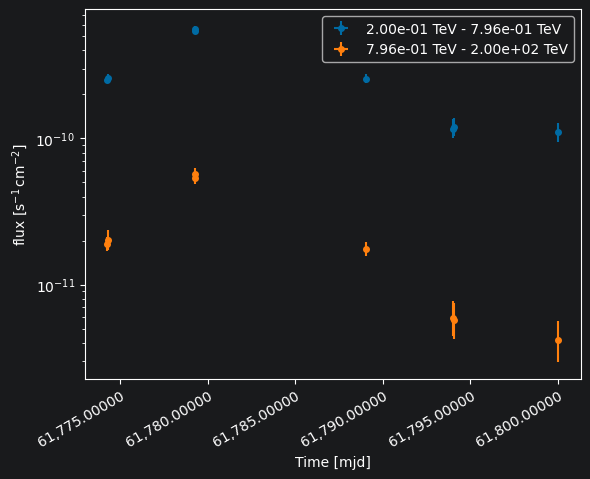

In [22]:
lc.plot(sed_type="flux", time_format="mjd", axis_name="time")

We can also rebin the light curve to larger, fixed number of time bins, or requesting a minimum TS:

In [23]:
lc_maker_new = LightCurveEstimator(
    energy_edges=[e_min, e_max],
    source=model_best_joint.name,
    time_intervals=time_intervals,
    selection_optional="all",
    n_jobs=6,
)
lc_all = lc_maker_new.run(datasets)

Time intervals selection:   0%|          | 0/1855 [00:00<?, ?it/s]

Time intervals:   0%|          | 0/8 [00:00<?, ?it/s]

In [24]:
# axis_new = get_rebinned_axis(lc_all, method="min-ts", ts_threshold=3000, axis_name="time")
axis_new = get_rebinned_axis(lc_all, method="fixed-bins", group_size=3, axis_name="time")
print(axis_new)

TimeMapAxis
-----------

  name           : time      
  nbins          : 3         
  reference time : 2028-01-04 06:05:01.174
  scale          : tt        
  time min.      : 2028-01-04 06:05:01.174
  time max.      : 2028-01-30 00:25:01.174
  total time     : 618.3333333333334 h



/cvmfs/sw.hess-experiment.eu/software/conda/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


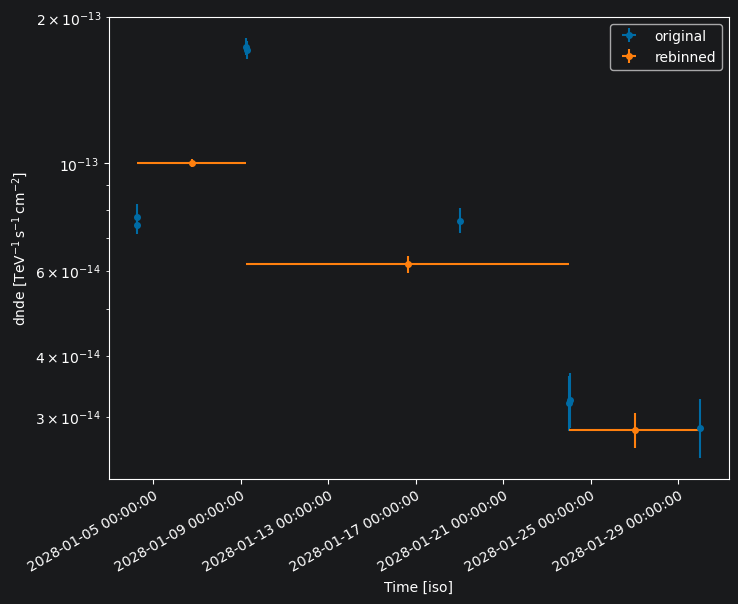

In [25]:
lc_new = lc_all.resample_axis(axis_new)

plt.figure(figsize=(8, 6))
ax = lc_all.plot(label="original")
lc_new.plot(ax=ax, label="rebinned")
plt.legend()
plt.show()

# Fractional and point-to-point variability

In [26]:
compute_lightcurve_fvar(lc, flux_quantity='flux').pprint_all()

    min_energy         max_energy            fvar              fvar_err          significance   
       TeV                TeV                                                                   
------------------ ------------------ ------------------ -------------------- ------------------
               0.2 0.7962143411069947 0.6500168174491727 0.025006392458963304 25.994026068169635
0.7962143411069947 199.99999999999991 0.9092775858189092   0.0480651005819387  18.91762577857969


In [27]:
compute_lightcurve_fpp(lc, flux_quantity='flux').pprint_all()

    min_energy         max_energy            fpp               fpp_err           significance   
       TeV                TeV                                                                   
------------------ ------------------ ------------------ -------------------- ------------------
               0.2 0.7962143411069947 0.5936814157919088 0.025020930314345737 23.727391760949907
0.7962143411069947 199.99999999999991 0.8683192472525687  0.04809046817891938 18.055953292490496


In [28]:
compute_lightcurve_doublingtime(lc, flux_quantity='flux').pprint_all()

    min_energy         max_energy        doublingtime       doubling_err      doubling_coord      halvingtime        halving_err       halving_coord   
       TeV                TeV                 s                  s                                     s                  s                            
------------------ ------------------ ------------------ ------------------ ------------------ ------------------ ------------------ ------------------
               0.2 0.7962143411069947 27717.549917542685  79202.07303708959 61774.260430254624 23287.828212845492 43657.619286305126 61779.260430254624
0.7962143411069947 199.99999999999991 12608.350535661055 24896.835772015835 61779.260430254624  23822.52618541848  264950.3606426539 61794.024319143515


# Hardness ratio diagrams

Let's compute the flux ratio of our two light curves, plot them against time, and against the overall flux (i.e. hardness ratio diagram).

Access the low-energy and high-energy light curves.

**Tip**: Remember that `RegionNDMap` holds quantities of `numpy.ndarray`s.

In [29]:
lc_lo = lc.flux.quantity[:, [0]].flatten()
lc_lo_err = lc.flux_err.quantity[:, [0]].flatten()

lc_hi = lc.flux.quantity[:, [1]].flatten()
lc_hi_err = lc.flux_err.quantity[:, [1]].flatten()

lc_tot = lc_lo+lc_hi
lc_tot_err = np.sqrt(lc_hi_err**2 + lc_lo_err**2)

In [30]:
flux_ratio = lc_hi/lc_lo

In [31]:
flux_ratio_err = flux_ratio * np.sqrt((lc_hi_err/lc_hi)**2+(lc_lo_err/lc_lo)**2)

Plot the flux ratio versus time

Text(0, 0.5, 'Hardness ratio (0.6 TeV-200.0 TeV/0.2 TeV-0.6 TeV)')

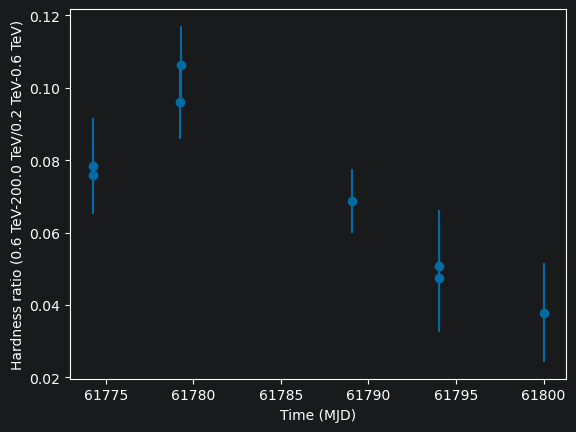

In [32]:
plt.errorbar(x=lc.geom.axes["time"].time_mid.mjd, y=flux_ratio, yerr=flux_ratio_err, fmt='o')
plt.xlabel("Time (MJD)")
plt.ylabel(
    f"Hardness ratio ({e_ranges[1][0]:.1f}-{e_ranges[1][1]:.1f}/{e_ranges[0][0]:.1f}-{e_ranges[0][1]:.1f})"
)

Finally, let's plot the hardness ratio diagram (integral flux in the whole energy range, versus the flux ratio)

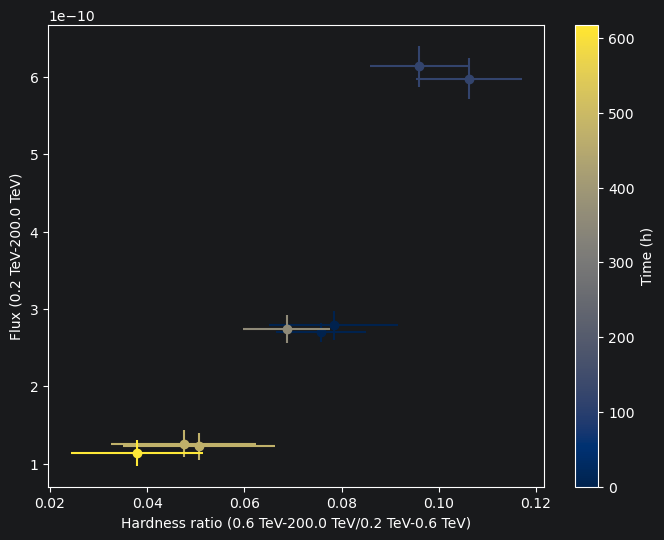

In [33]:
fig, ax = plt.subplots(figsize=(8,6))

t = ((lc.geom.axes["time"].time_mid.mjd-lc.geom.axes["time"].time_mid.mjd[0]) * u.d).to(u.h)

cmap_norm = matplotlib.colors.Normalize(vmin=min(t.value), vmax=max(t.value))
mapper = matplotlib.cm.ScalarMappable(norm=cmap_norm, cmap='cividis')
time_colors = np.array([(mapper.to_rgba(_)) for _ in t.value])

for _x, _y, _ex, _ey, _color in zip(flux_ratio, lc_tot, flux_ratio_err, lc_tot_err, time_colors):
    ax.plot(_x, _y, 'o', color=_color)
    ax.errorbar(
        x=_x,
        xerr=_ex,
        y=_y,
        yerr=_ey,
        color=_color,
    )
ax.set_xlabel(
    f"Hardness ratio ({e_ranges[1][0]:.1f}-{e_ranges[1][1]:.1f}/{e_ranges[0][0]:.1f}-{e_ranges[0][1]:.1f})"
)
ax.set_ylabel(f"Flux ({e_ranges[2][0]:.1f}-{e_ranges[2][1]:.1f})")
fig.colorbar(mapper, ax=ax, orientation='vertical', label="Time (h)")